In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("car_data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
print(df.shape)
df.info()
df.isnull().sum()       # missing values per column
df.duplicated().sum()   # number of duplicate rows

(301, 9)
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


np.int64(2)

In [4]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [5]:
df[df.duplicated(keep=False)]

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(299, 9)


In [7]:
for col in ["Fuel_Type", "Selling_type", "Transmission", "Owner"]:
    print(df[col].value_counts(), "\n")

print("Unique car names:", df["Car_Name"].nunique())

Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64 

Selling_type
Dealer        193
Individual    106
Name: count, dtype: int64 

Transmission
Manual       260
Automatic     39
Name: count, dtype: int64 

Owner
0    288
1     10
3      1
Name: count, dtype: int64 

Unique car names: 98


Explore, and ask what drives price

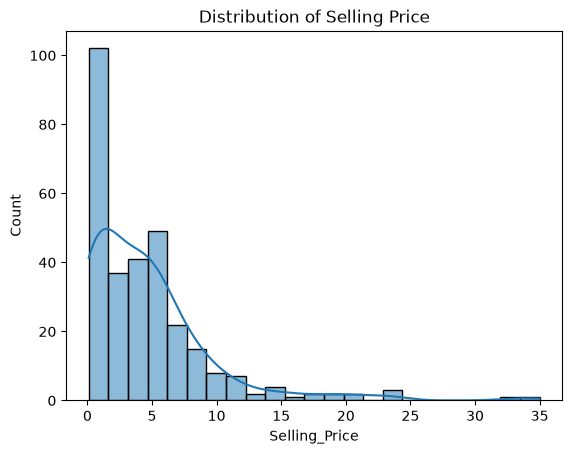

In [8]:
sns.histplot(df["Selling_Price"], kde=True)
plt.title("Distribution of Selling Price")
plt.show()

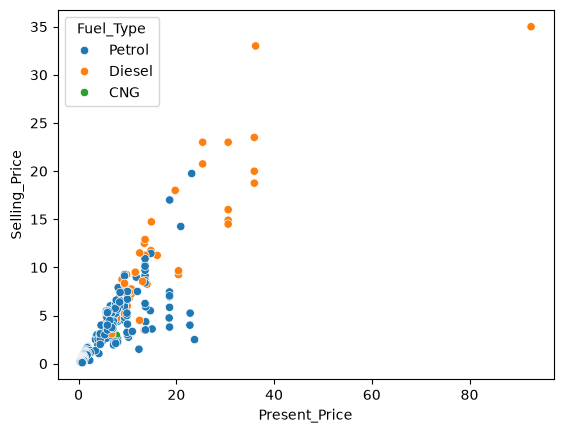

In [9]:
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Fuel_Type")
plt.show()

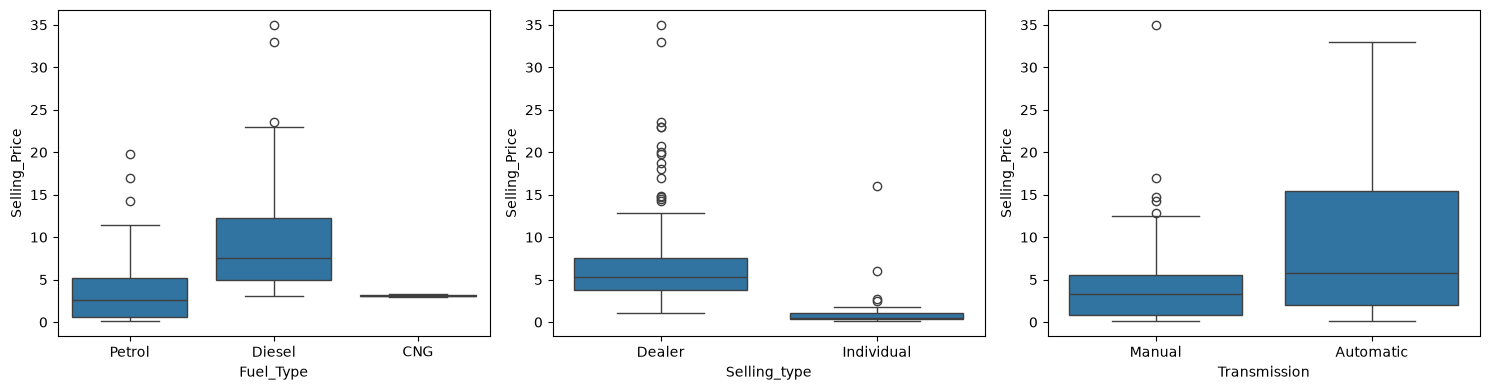

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Fuel_Type", "Selling_type", "Transmission"]):
    sns.boxplot(data=df, x=col, y="Selling_Price", ax=ax)
plt.tight_layout()
plt.show()

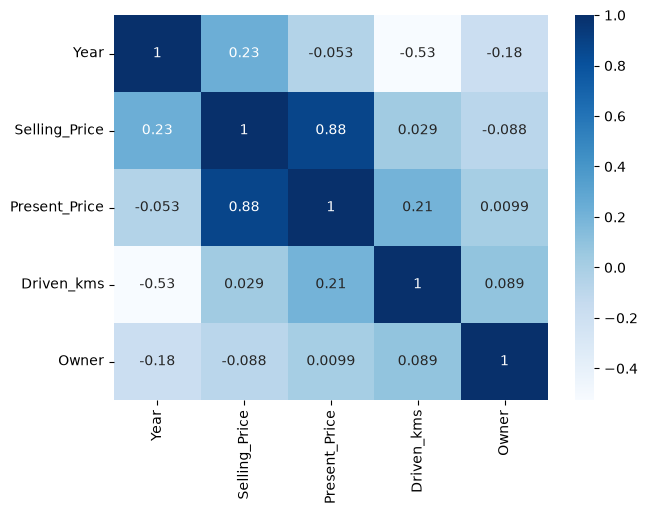

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="Blues")
plt.show()

In [12]:
df[df["Driven_kms"] > 200000]

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
177,Honda Karizma,2010,0.31,1.05,213000,Petrol,Individual,Manual,0
194,Activa 3g,2008,0.17,0.52,500000,Petrol,Individual,Automatic,0


In [13]:
df[df["Present_Price"] > 50]

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
85,land cruiser,2010,35.0,92.6,78000,Diesel,Dealer,Manual,0


Feature Engineering 

In [14]:
df["Car_Age"] = df["Year"].max() - df["Year"]

In [15]:
df_model = df.drop(columns=["Car_Name", "Year"])

df_model = pd.get_dummies(
    df_model,
    columns=["Fuel_Type", "Selling_type", "Transmission"],
    drop_first=True,
    dtype=int,
)
df_model.head()

,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,4,0,1,0,1
1,4.75,9.54,43000,0,5,1,0,0,1
2,7.25,9.85,6900,0,1,0,1,0,1
3,2.85,4.15,5200,0,7,0,1,0,1
4,4.60,6.87,42450,0,4,1,0,0,1


In [16]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns="Selling_Price")
y = df_model["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(239, 8) (60, 8)


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name}: MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.3f}")

In [18]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

evaluate("Baseline (always the mean)", DummyRegressor(strategy="mean"))
evaluate("Linear Regression", LinearRegression())
evaluate("Random Forest", RandomForestRegressor(random_state=42))

Baseline (always the mean): MAE=3.33  RMSE=5.08  R2=-0.000
Linear Regression: MAE=1.47  RMSE=2.52  R2=0.753
Random Forest: MAE=1.45  RMSE=3.46  R2=0.536
